In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler


In [2]:
# 1. Cargar el archivo CSV
df = pd.read_csv("")

# 2. Agrega AQUÍ todas las columnas numéricas que quieras analizar (pueden ser más de 2)
columnas_analisis = [
    "Item_Weight",
    "Item_Visibility",
    "Outlet_Establishment_Year",
    "Item_Outlet_Sales",
]
X_seleccion = df[columnas_analisis]

# 3. Limpieza de registros con valores vacíos (NaN)
X_limpio = X_seleccion.fillna(X_seleccion.median())

# 4. Normalizar los datos (Obligatorio antes de aplicar PCA y K-Means)
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_limpio)

# 5. Aplicar PCA para reducir las variables a 2 dimensiones visualizables
pca = PCA(n_components=2)
X = pca.fit_transform(X_escalado)

# Calcular el porcentaje de información que se logró conservar
varianza_explicada = np.sum(pca.explained_variance_ratio_) * 100

print(f"Dataset procesado correctamente.")
print(f"Filas válidas: {X.shape[0]} | Variables originales: {len(columnas_analisis)}")
print(
    f"PCA redujo los datos a 2 componentes, reteniendo el {varianza_explicada:.2f}% de la información original."
)


NameError: name 'pd' is not defined

In [4]:
# Probar configuraciones de clusters para evaluar rendimiento
rango_k = [2, 3, 4, 5, 6]

print("--- Evaluación de Coeficiente de Silueta (con datos PCA) ---")
for n_clusters in rango_k:
    clusterer = KMeans(n_clusters=n_clusters, random_state=42, n_init="auto")
    cluster_labels = clusterer.fit_predict(X)

    # El score se calcula sobre las dimensiones de PCA donde se agrupará y graficará
    silhouette_avg = silhouette_score(X, cluster_labels)
    print(
        f"Para K = {n_clusters} -> El Silhouette Score promedio es: {silhouette_avg:.4f}"
    )


--- Evaluación de Coeficiente de Silueta (con datos PCA) ---
Para K = 2 -> El Silhouette Score promedio es: 0.3767
Para K = 3 -> El Silhouette Score promedio es: 0.4847
Para K = 4 -> El Silhouette Score promedio es: 0.5415
Para K = 5 -> El Silhouette Score promedio es: 0.5440
Para K = 6 -> El Silhouette Score promedio es: 0.5112


/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_k

/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/edwynmartinezcarrillo/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_k

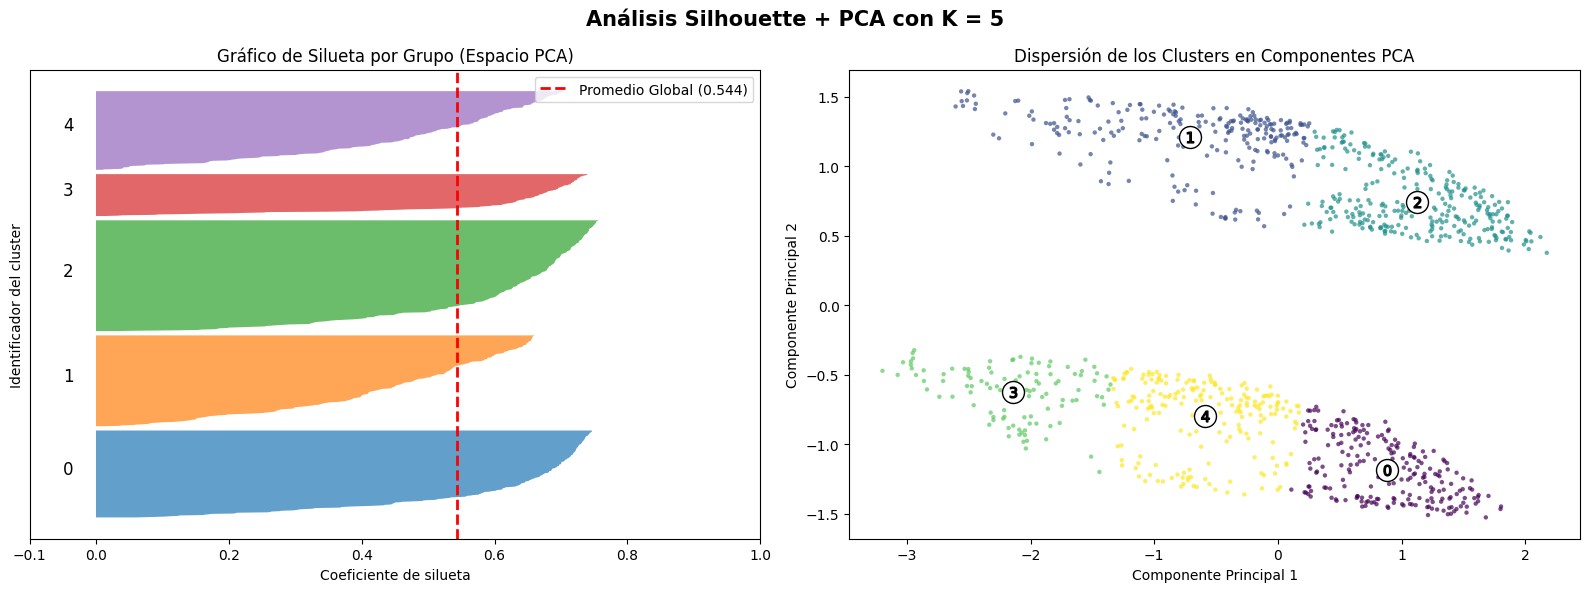

In [5]:
# DEFINE EL K CON MEJOR RENDIMIENTO BASADO EN TU CELDA 3
k_elegido = 5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Entrenar el modelo final en el espacio bidimensional de PCA
modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init="auto")
etiquetas = modelo_final.fit_predict(X)
valores_silueta = silhouette_samples(X, etiquetas)
score_global = silhouette_score(X, etiquetas)

y_limite_inferior = 10
for i in range(k_elegido):
    siluetas_cluster_i = valores_silueta[etiquetas == i]
    siluetas_cluster_i.sort()

    tamaño_cluster_i = siluetas_cluster_i.shape[0]
    y_limite_superior = y_limite_inferior + tamaño_cluster_i

    ax1.fill_betweenx(
        np.arange(y_limite_inferior, y_limite_superior),
        0,
        siluetas_cluster_i,
        alpha=0.7,
    )
    ax1.text(
        -0.05, y_limite_inferior + 0.5 * tamaño_cluster_i, str(i), fontsize=12
    )
    y_limite_inferior = y_limite_superior + 10

# Propiedades del gráfico de Siluetas (Izquierda)
ax1.set_title("Gráfico de Silueta por Grupo (Espacio PCA)", fontsize=12)
ax1.set_xlabel("Coeficiente de silueta")
ax1.set_ylabel("Identificador del cluster")
ax1.axvline(
    x=score_global,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Promedio Global ({score_global:.3f})",
)
ax1.set_yticks([])
ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
ax1.legend(loc="upper right")

# Propiedades de la gráfica de Dispersión PCA (Derecha)
ax2.scatter(X[:, 0], X[:, 1], marker=".", s=40, lw=0, alpha=0.7, c=etiquetas)

# Centros de los clusters en el espacio PCA
centros = modelo_final.cluster_centers_
ax2.scatter(
    centros[:, 0],
    centros[:, 1],
    marker="o",
    c="white",
    alpha=1,
    s=250,
    edgecolor="k",
)

for i, c in enumerate(centros):
    ax2.scatter(c[0], c[1], marker=f"${i}$", alpha=1, s=60, edgecolor="k")

ax2.set_title("Dispersión de los Clusters en Componentes PCA", fontsize=12)
ax2.set_xlabel("Componente Principal 1")
ax2.set_ylabel("Componente Principal 2")

plt.suptitle(
    f"Análisis Silhouette + PCA con K = {k_elegido}",
    fontsize=15,
    fontweight="bold",
)
plt.tight_layout()
plt.show()


In [6]:
# 1. Cargar el archivo CSV
df = pd.read_csv("/Users/edwynmartinezcarrillo/Documents/Proyecto_doctorado/Programas/python/minucias_izq27.csv")

# 2. Agrega AQUÍ todas las columnas numéricas que quieras analizar (pueden ser más de 2)
columnas_analisis = ["Tipo", "X", "Y", "Angulo_Grad"]
X_seleccion = df[columnas_analisis]

# 3. Limpieza de registros con valores vacíos (NaN)
X_limpio = X_seleccion.dropna()

# 4. Normalizar los datos (Obligatorio antes de aplicar PCA y K-Means)
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_limpio)

# 5. Aplicar PCA para reducir las variables a 2 dimensiones visualizables
pca = PCA(n_components=2)
X = pca.fit_transform(X_escalado)

# Calcular el porcentaje de información que se logró conservar
varianza_explicada = np.sum(pca.explained_variance_ratio_) * 100

print(f"Dataset procesado correctamente.")
print(f"Filas válidas: {X.shape[0]} | Variables originales: {len(columnas_analisis)}")
print(
    f"PCA redujo los datos a 2 componentes, reteniendo el {varianza_explicada:.2f}% de la información original."
)


Dataset procesado correctamente.
Filas válidas: 51 | Variables originales: 4
PCA redujo los datos a 2 componentes, reteniendo el 76.58% de la información original.


In [7]:
# Probar configuraciones de clusters para evaluar rendimiento
rango_k = [2, 3, 4, 5, 6]

print("--- Evaluación de Coeficiente de Silueta (con datos PCA) ---")
for n_clusters in rango_k:
    clusterer = KMeans(n_clusters=n_clusters, random_state=42, n_init="auto")
    cluster_labels = clusterer.fit_predict(X)

    # El score se calcula sobre las dimensiones de PCA donde se agrupará y graficará
    silhouette_avg = silhouette_score(X, cluster_labels)
    print(
        f"Para K = {n_clusters} -> El Silhouette Score promedio es: {silhouette_avg:.4f}"
    )


--- Evaluación de Coeficiente de Silueta (con datos PCA) ---
Para K = 2 -> El Silhouette Score promedio es: 0.4374
Para K = 3 -> El Silhouette Score promedio es: 0.5356
Para K = 4 -> El Silhouette Score promedio es: 0.5628
Para K = 5 -> El Silhouette Score promedio es: 0.5994
Para K = 6 -> El Silhouette Score promedio es: 0.5934


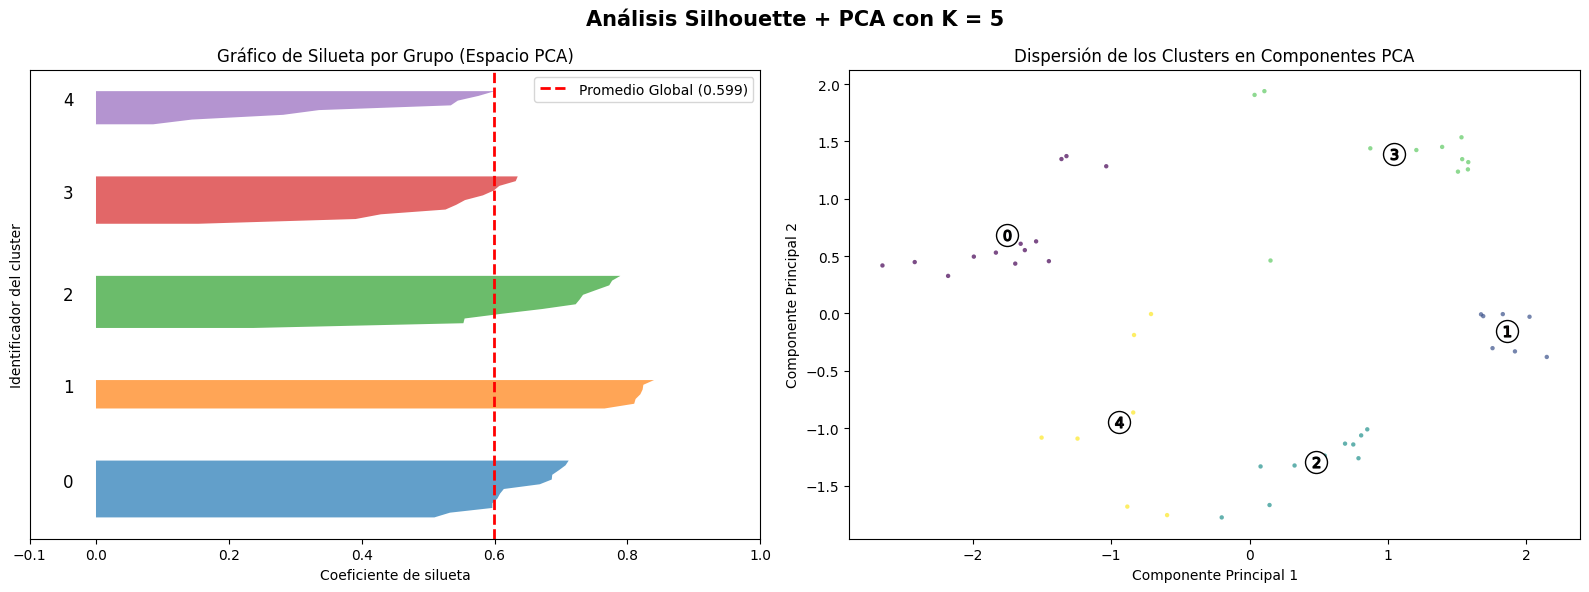

In [8]:
# DEFINE EL K CON MEJOR RENDIMIENTO BASADO EN TU CELDA 3
k_elegido = 5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Entrenar el modelo final en el espacio bidimensional de PCA
modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init="auto")
etiquetas = modelo_final.fit_predict(X)
valores_silueta = silhouette_samples(X, etiquetas)
score_global = silhouette_score(X, etiquetas)

y_limite_inferior = 10
for i in range(k_elegido):
    siluetas_cluster_i = valores_silueta[etiquetas == i]
    siluetas_cluster_i.sort()

    tamaño_cluster_i = siluetas_cluster_i.shape[0]
    y_limite_superior = y_limite_inferior + tamaño_cluster_i

    ax1.fill_betweenx(
        np.arange(y_limite_inferior, y_limite_superior),
        0,
        siluetas_cluster_i,
        alpha=0.7,
    )
    ax1.text(
        -0.05, y_limite_inferior + 0.5 * tamaño_cluster_i, str(i), fontsize=12
    )
    y_limite_inferior = y_limite_superior + 10

# Propiedades del gráfico de Siluetas (Izquierda)
ax1.set_title("Gráfico de Silueta por Grupo (Espacio PCA)", fontsize=12)
ax1.set_xlabel("Coeficiente de silueta")
ax1.set_ylabel("Identificador del cluster")
ax1.axvline(
    x=score_global,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Promedio Global ({score_global:.3f})",
)
ax1.set_yticks([])
ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
ax1.legend(loc="upper right")

# Propiedades de la gráfica de Dispersión PCA (Derecha)
ax2.scatter(X[:, 0], X[:, 1], marker=".", s=40, lw=0, alpha=0.7, c=etiquetas)

# Centros de los clusters en el espacio PCA
centros = modelo_final.cluster_centers_
ax2.scatter(
    centros[:, 0],
    centros[:, 1],
    marker="o",
    c="white",
    alpha=1,
    s=250,
    edgecolor="k",
)

for i, c in enumerate(centros):
    ax2.scatter(c[0], c[1], marker=f"${i}$", alpha=1, s=60, edgecolor="k")

ax2.set_title("Dispersión de los Clusters en Componentes PCA", fontsize=12)
ax2.set_xlabel("Componente Principal 1")
ax2.set_ylabel("Componente Principal 2")

plt.suptitle(
    f"Análisis Silhouette + PCA con K = {k_elegido}",
    fontsize=15,
    fontweight="bold",
)
plt.tight_layout()
plt.show()
